# 03 - Modelado baseline y tratamiento del desbalance

**Proyecto:** Predicción de ausentismo a turnos médicos (*No-Show*)
**Fase CRISP-DM:** Modelado

**Objetivo:** entrenar y comparar los algoritmos de clasificación con sus parámetros por defecto, y evaluar si las estrategias de tratamiento del desbalance mejoran su desempeño. El resultado de este notebook es la selección de los **modelos candidatos** que se optimizarán con Optuna en el notebook 04.

**Experimentos registrados en MLflow:**

| Experimento | Contenido |
|---|---|
| `01_baseline` | Todos los modelos con parámetros por defecto y sin tratamiento del desbalance |
| `02_desbalance` | Cada modelo con ponderación de clases, submuestreo aleatorio y SMOTE |

**Salidas:** figuras (prefijo `mod_`), tablas en `reports/tables/`, candidatos en `reports/tables/mod_candidatos.csv` y resumen en `reports/tables/mod_resumen.md`.

> **Tiempo de ejecución estimado con el dataset completo:** pocos minutos (Random Forest con SMOTE es la configuración más lenta).

## 0. Configuración

In [1]:
# Interruptor de datos: True = muestra de desarrollo, False = dataset completo
USAR_MUESTRA = False

In [2]:
import hashlib
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src import config
from src.data import cargar_procesados, ruta_procesados
from src.evaluation import NOMBRES_METRICAS, evaluar_cv, resumir_folds, umbral_f1_optimo
from src.modeling import ESTRATEGIAS, MODELOS, atributos_de, crear_pipeline
from src.reporting import guardar_figura, guardar_tabla, tabla_markdown
from src.tracking import configurar_experimento, etiquetas_base, exportar_corridas, registrar_corrida

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

resumen = {"Datos utilizados": "Muestra de desarrollo" if USAR_MUESTRA else "Dataset completo"}

## 1. Carga de los datos y control de trazabilidad

Se carga el dataset procesado por el notebook 02 y se verifica que su *hash* SHA-256 coincida con el registrado en los metadatos. Así se garantiza que todos los modelos se entrenan con exactamente los mismos datos que se prepararon y documentaron.

**Solo se usa el conjunto de entrenamiento.** El conjunto de prueba no se toca hasta el notebook 05.

In [3]:
ruta = ruta_procesados(USAR_MUESTRA)
etiquetas = etiquetas_base(USAR_MUESTRA)
hash_actual = hashlib.sha256(ruta.read_bytes()).hexdigest()
assert hash_actual == etiquetas["dataset_sha256"], "El dataset procesado no coincide con el registrado en los metadatos"
print(f"Hash verificado: {hash_actual[:16]}...")

datos = cargar_procesados(USAR_MUESTRA)
train = datos[datos["particion"] == "train"].reset_index(drop=True)
y = train[config.TARGET]
folds = train["fold"].to_numpy()
ratio_clases = (y == 0).sum() / (y == 1).sum()

resumen["Turnos de entrenamiento"] = f"{len(train):,}"
resumen["Tasa de no-show (entrenamiento)"] = f"{y.mean():.2%}"
print(f"Entrenamiento: {len(train):,} turnos | no-show: {y.mean():.2%} | relación de clases: {ratio_clases:.2f}")
print(f"Folds: {sorted(np.unique(folds))}")
etiquetas

Hash verificado: 40d361e54c4cd001...


Entrenamiento: 88,301 turnos | no-show: 20.10% | relación de clases: 3.98
Folds: [0, 1, 2, 3, 4]


{'datos': 'Dataset completo',
 'dataset_sha256': '40d361e54c4cd001e1c062e326c199206e44089db0d0ceb24d7879bd8a0413e6',
 'semilla': '42',
 'git_commit': '43c7907'}

## 2. Diseño experimental

### 2.1. Protocolo de evaluación

- **Validación cruzada con 5 folds fijos** (columna `fold`, estratificados y agrupados por paciente). Todos los modelos se evalúan con exactamente las mismas particiones, por lo que las diferencias entre ellos se pueden comparar fold a fold.
- **Pipeline completo dentro de cada fold:** el preprocesamiento (incluida la codificación por objetivo del barrio) y el remuestreo se ajustan solo con los datos de entrenamiento del fold. La validación siempre se hace sobre datos reales, sin remuestrear.
- **Predicciones fuera de fold (OOF):** cada turno de entrenamiento recibe una probabilidad de un modelo que no lo vio. Se usan para las curvas ROC y PR y para analizar el umbral.

### 2.2. Métricas

| Métrica | Tipo | Por qué se usa |
|---|---|---|
| **PR-AUC** (precisión promedio) | Independiente del umbral | **Métrica principal.** Se concentra en la clase minoritaria; su piso es la tasa de no-show (~0,20) |
| ROC-AUC | Independiente del umbral | Capacidad general de ordenar los turnos por riesgo; piso 0,5 |
| Recall, precisión y F1 (no-show) | Con umbral 0,5 | Desempeño operativo sobre la clase de interés |
| Exactitud balanceada | Con umbral 0,5 | Promedio del recall de ambas clases; no se infla con el desbalance |
| Exactitud | Con umbral 0,5 | Solo como referencia (engañosa con clases desbalanceadas) |
| Brier | Calibración | Error cuadrático de la probabilidad; mide si las probabilidades son confiables (menor es mejor) |
| PR-AUC en entrenamiento | Diagnóstico | Si es mucho mayor que la de validación, el modelo está sobreajustado |

Las métricas con umbral se calculan con el umbral por defecto de 0,5 para mostrar el efecto del desbalance. El umbral definitivo se ajustará en el notebook 05.

### 2.3. Algoritmos

| Algoritmo | Descripción | Visto en la materia |
|---|---|---|
| Dummy (clase a priori) | Predice siempre la probabilidad de la clase mayoritaria. Es el piso de referencia | — |
| Regresión Logística | Modelo lineal que estima la probabilidad mediante la función logística. Interpretable y bien calibrado | Regresión (Unidad III) |
| Árbol de Decisión | Particiona el espacio de atributos con reglas de tipo "si... entonces". Muy interpretable, pero sin poda tiende a sobreajustar | Sí (Unidad III) |
| Random Forest | Ensamble de árboles entrenados con muestras *bootstrap* y subconjuntos aleatorios de atributos (*bagging*). Reduce la varianza del árbol individual | No |
| LightGBM | *Gradient boosting*: construye árboles secuencialmente, cada uno corrigiendo los errores del anterior. Usa histogramas y crecimiento por hojas para ser muy eficiente (Ke et al., 2017) | No |
| XGBoost | *Gradient boosting* con regularización explícita de la complejidad de los árboles (Chen y Guestrin, 2016) | No |

### 2.4. Estrategias de tratamiento del desbalance

| Estrategia | Descripción |
|---|---|
| Sin tratamiento | Se entrena con la distribución original (~4:1) |
| Ponderación de clases | Cada error sobre la clase minoritaria pesa más en la función de pérdida, en proporción inversa a la frecuencia de la clase. No modifica los datos |
| Submuestreo aleatorio | Se eliminan al azar turnos de la clase mayoritaria hasta igualar las clases. Pierde información |
| SMOTE | Genera turnos sintéticos de la clase minoritaria interpolando entre vecinos cercanos (Chawla et al., 2002) |

**Limitación de SMOTE en este problema:** la interpolación genera valores intermedios en atributos binarios o enteros (por ejemplo, `diabetes = 0,4` o `2,7` turnos previos) que no existen en los datos reales. La variante SMOTE-NC trata los atributos categóricos por separado; se usa SMOTE estándar por ser la técnica clásica y como referencia comparativa. Las consecuencias de esta limitación se analizan con evidencia en la sección 4.3.

In [4]:
def ejecutar_configuracion(modelo, estrategia):
    """Evalúa una configuración con los folds fijos y devuelve las métricas por fold y las OOF."""
    pipeline = crear_pipeline(modelo, estrategia, ratio_clases)
    por_fold, oof = evaluar_cv(pipeline, train[atributos_de(modelo)], y, folds)
    return pipeline, por_fold, oof


def parametros_corrida(modelo, estrategia, pipeline):
    """Parámetros que se registran en MLflow: configuración y parámetros del clasificador."""
    clasificador = pipeline.named_steps["clasificador"].get_params()
    simples = {f"clf__{k}": v for k, v in clasificador.items() if isinstance(v, (int, float, str, bool, type(None)))}
    return {"modelo": modelo, "estrategia": estrategia, "familia": MODELOS[modelo][0],
            "n_atributos": len(atributos_de(modelo)), "n_folds": int(len(np.unique(folds))), **simples}


resultados = {}  # (modelo, estrategia) -> {"por_fold": DataFrame, "oof": array, "run_id": str}

## 3. Experimento 1: modelos con parámetros por defecto

Todos los algoritmos se entrenan con sus parámetros por defecto (solo se fijan la semilla, el paralelismo y la verbosidad) y sin tratamiento del desbalance. Este experimento establece la línea base contra la que se comparan las estrategias de desbalance y la optimización posterior.

In [5]:
configurar_experimento("baseline", USAR_MUESTRA)

for modelo in MODELOS:
    with mlflow.start_run(run_name=f"{modelo}__ninguna"):  # la duración registrada incluye el entrenamiento
        pipeline, por_fold, oof = ejecutar_configuracion(modelo, "ninguna")
        run_id = registrar_corrida(
            nombre_corrida=f"{modelo}__ninguna",
            parametros=parametros_corrida(modelo, "ninguna", pipeline),
            metricas=resumir_folds(por_fold),
            etiquetas={**etiquetas, "etapa": "baseline"},
            tablas={"metricas_por_fold": por_fold},
        )
    resultados[(modelo, "ninguna")] = {"por_fold": por_fold, "oof": oof, "run_id": run_id}
    print(f"{MODELOS[modelo][1]:<24} PR-AUC = {por_fold['pr_auc'].mean():.4f} ± {por_fold['pr_auc'].std():.4f}"
          f"  ({por_fold['segundos_ajuste'].sum():.1f} s)")

Dummy (clase a priori)   PR-AUC = 0.2010 ± 0.0031  (0.4 s)


Regresión Logística      PR-AUC = 0.3658 ± 0.0153  (1.8 s)


Árbol de Decisión        PR-AUC = 0.2329 ± 0.0051  (2.1 s)


Random Forest            PR-AUC = 0.3536 ± 0.0099  (6.2 s)


LightGBM                 PR-AUC = 0.3814 ± 0.0143  (1.5 s)


XGBoost                  PR-AUC = 0.3659 ± 0.0093  (1.5 s)


In [6]:
def tabla_resultados(claves):
    """Tabla con media y desvío de cada métrica para las configuraciones indicadas."""
    filas = []
    for modelo, estrategia in claves:
        pf = resultados[(modelo, estrategia)]["por_fold"]
        fila = {"Modelo": MODELOS[modelo][1], "Estrategia": ESTRATEGIAS[estrategia]}
        for m in ["pr_auc", "roc_auc", "recall", "precision", "f1", "balanced_accuracy", "accuracy", "brier"]:
            fila[NOMBRES_METRICAS[m]] = pf[m].mean()
        fila["PR-AUC (desvío)"] = pf["pr_auc"].std()
        fila["PR-AUC entrenamiento"] = pf["pr_auc_train"].mean()
        fila["Segundos (5 folds)"] = pf["segundos_ajuste"].sum()
        filas.append(fila)
    return pd.DataFrame(filas)


tabla_baseline = tabla_resultados([(m, "ninguna") for m in MODELOS]).sort_values("PR-AUC", ascending=False)
guardar_tabla(tabla_baseline, "mod_baseline")
tabla_baseline

,Modelo,Estrategia,PR-AUC,ROC-AUC,Recall (no-show),Precisión (no-show),F1 (no-show),Exactitud balanceada,Exactitud,Brier,PR-AUC (desvío),PR-AUC entrenamiento,Segundos (5 folds)
4,LightGBM,Sin tratamiento,0.3814,0.7442,0.0380,0.5181,0.0708,0.5146,0.7996,0.1415,0.0143,0.4898,1.4840
5,XGBoost,Sin tratamiento,0.3659,0.7352,0.0788,0.4510,0.1341,0.5274,0.7957,0.1441,0.0093,0.5907,1.4671
1,Regresión Logística,Sin tratamiento,0.3658,0.7361,0.0302,0.4983,0.0570,0.5113,0.7990,0.1429,0.0153,0.3676,1.8227
3,Random Forest,Sin tratamiento,0.3536,0.7244,0.1139,0.4265,0.1796,0.5377,0.7911,0.1469,0.0099,1.0000,6.2399
2,Árbol de Decisión,Sin tratamiento,0.2329,0.5668,0.3264,0.2984,0.3118,0.5667,0.7104,0.2892,0.0051,1.0000,2.0757
0,Dummy (clase a priori),Sin tratamiento,0.2010,0.5000,0.0000,0.0000,0.0000,0.5000,0.7990,0.1606,0.0031,0.2010,0.3879


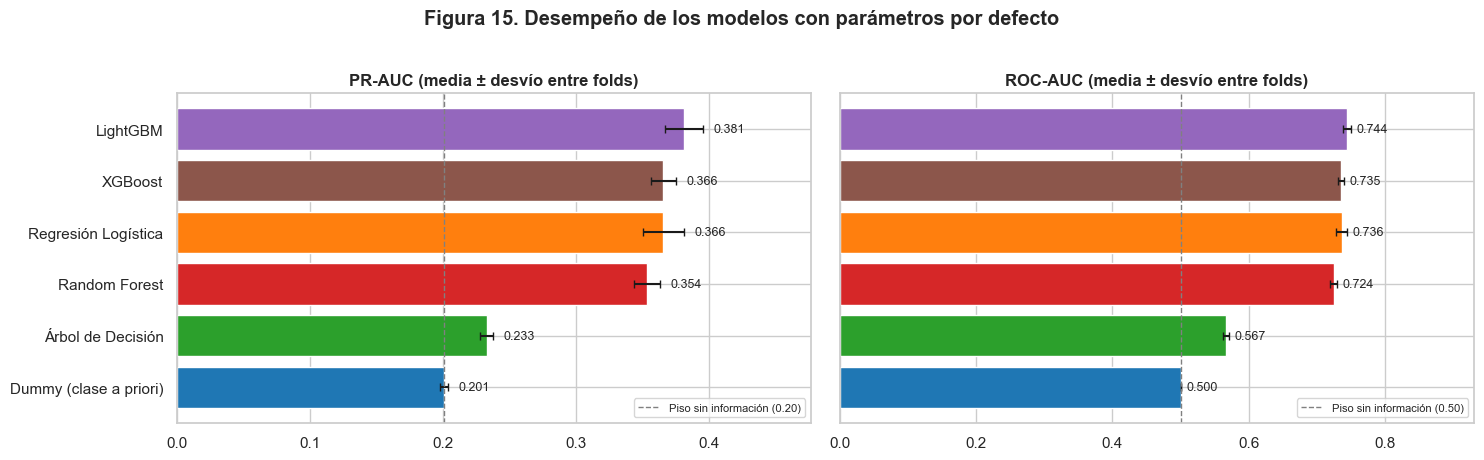

In [7]:
nombres = [MODELOS[m][1] for m in MODELOS]
colores = dict(zip(nombres, sns.color_palette("tab10", len(nombres))))
orden = tabla_baseline["Modelo"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, metrica, piso in [(axes[0], "PR-AUC", y.mean()), (axes[1], "ROC-AUC", 0.5)]:
    medias = [resultados[(m, "ninguna")]["por_fold"][metrica.lower().replace("-", "_")].mean() for m in MODELOS]
    desvios = [resultados[(m, "ninguna")]["por_fold"][metrica.lower().replace("-", "_")].std() for m in MODELOS]
    serie = pd.DataFrame({"media": medias, "desvio": desvios}, index=nombres).loc[orden]
    ax.barh(serie.index[::-1], serie["media"][::-1], xerr=serie["desvio"][::-1],
            color=[colores[n] for n in serie.index[::-1]], capsize=3)
    ax.axvline(piso, color="gray", ls="--", lw=1, label=f"Piso sin información ({piso:.2f})")
    for i, (v, d) in enumerate(zip(serie["media"][::-1], serie["desvio"][::-1])):
        ax.text(v + d + 0.008, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_title(f"{metrica} (media ± desvío entre folds)")
    ax.set_xlim(0, max(serie["media"].max() * 1.25, piso * 1.3))
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Figura 15. Desempeño de los modelos con parámetros por defecto", fontweight="bold", y=1.02)
fig.tight_layout()
guardar_figura(fig, "mod_01_baseline_metricas")
plt.show()

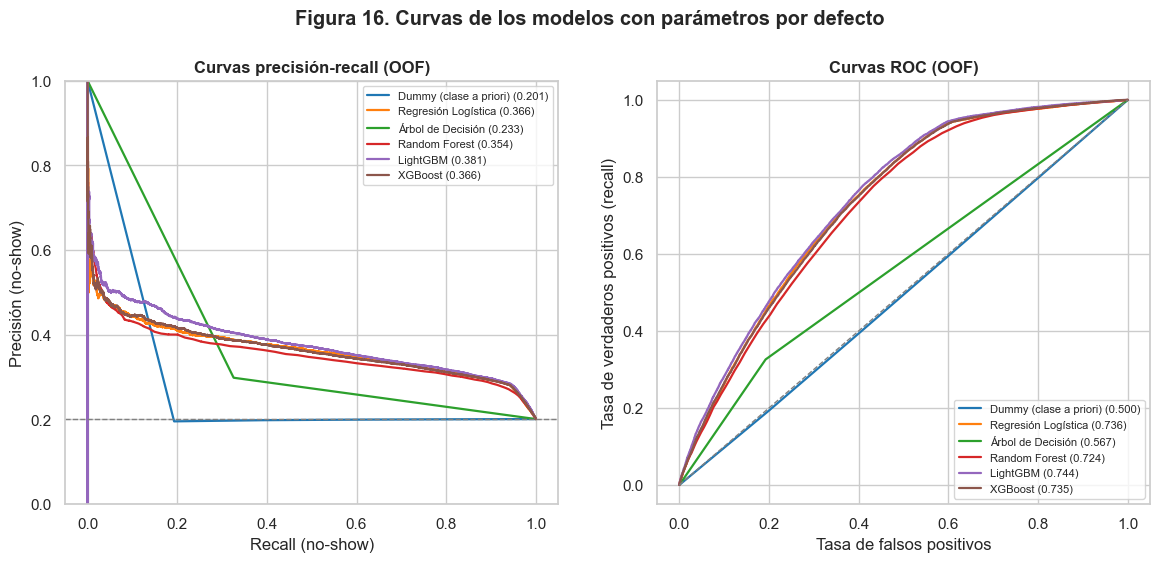

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for modelo in MODELOS:
    oof = resultados[(modelo, "ninguna")]["oof"]
    nombre = MODELOS[modelo][1]
    prec, rec, _ = precision_recall_curve(y, oof)
    fpr, tpr, _ = roc_curve(y, oof)
    pf = resultados[(modelo, "ninguna")]["por_fold"]
    axes[0].plot(rec, prec, color=colores[nombre], lw=1.6, label=f"{nombre} ({pf['pr_auc'].mean():.3f})")
    axes[1].plot(fpr, tpr, color=colores[nombre], lw=1.6, label=f"{nombre} ({pf['roc_auc'].mean():.3f})")
axes[0].axhline(y.mean(), color="gray", ls="--", lw=1)
axes[0].set(xlabel="Recall (no-show)", ylabel="Precisión (no-show)", title="Curvas precisión-recall (OOF)", ylim=(0, 1))
axes[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[1].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)", title="Curvas ROC (OOF)")
for ax in axes:
    ax.legend(fontsize=8, loc="upper right" if ax is axes[0] else "lower right")
fig.suptitle("Figura 16. Curvas de los modelos con parámetros por defecto", fontweight="bold", y=1.01)
guardar_figura(fig, "mod_02_baseline_curvas")
plt.show()

### 3.1. Diagnóstico de sobreajuste

Se compara la PR-AUC sobre los datos de entrenamiento de cada fold con la PR-AUC de validación. Una brecha grande indica que el modelo memoriza los datos de entrenamiento en lugar de aprender patrones generalizables.

**Detalle técnico.** El `TargetEncoder` codifica el barrio de dos formas: al ajustarse usa validación cruzada interna (cada turno se codifica sin su propio resultado) y al predecir usa las tasas de todo el entrenamiento. Si el desempeño de entrenamiento se midiera con la segunda codificación, los modelos de árboles recibirían valores distintos de los que usaron para aprender sus cortes, y el sobreajuste quedaría **subestimado**. Por eso la PR-AUC de entrenamiento se calcula con la codificación de ajuste (función `proba_entrenamiento` en `src/evaluation.py`). Este efecto se detectó al verificar que un árbol sin poda no alcanzaba una PR-AUC de entrenamiento cercana a 1.

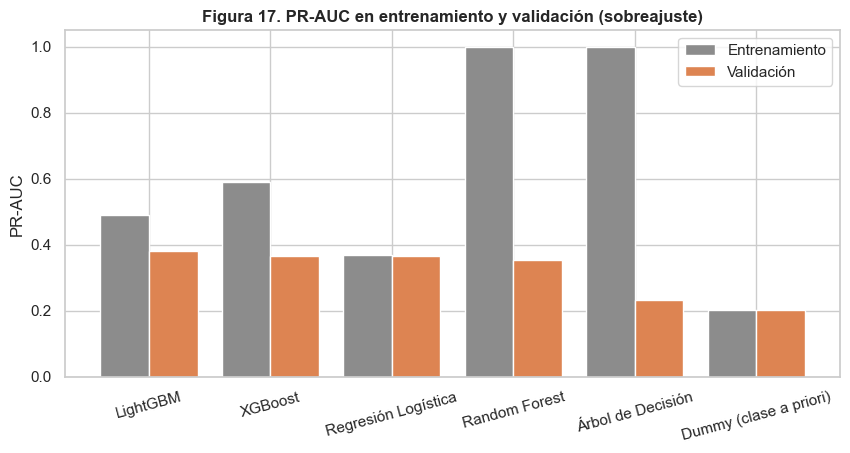

,PR-AUC entrenamiento,PR-AUC validación,Brecha
Modelo,,,
Árbol de Decisión,1.0000,0.2329,0.7671
Random Forest,1.0000,0.3536,0.6464
XGBoost,0.5907,0.3659,0.2248
LightGBM,0.4898,0.3814,0.1084
Regresión Logística,0.3676,0.3658,0.0018
Dummy (clase a priori),0.2010,0.2010,0.0000


In [9]:
brecha = tabla_baseline.set_index("Modelo")[["PR-AUC entrenamiento", "PR-AUC"]].rename(columns={"PR-AUC": "PR-AUC validación"})
brecha["Brecha"] = brecha["PR-AUC entrenamiento"] - brecha["PR-AUC validación"]

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(brecha))
ax.bar(x - 0.2, brecha["PR-AUC entrenamiento"], width=0.4, color="#8C8C8C", label="Entrenamiento")
ax.bar(x + 0.2, brecha["PR-AUC validación"], width=0.4, color="#DD8452", label="Validación")
ax.set_xticks(x)
ax.set_xticklabels(brecha.index, rotation=15)
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 1.05)
ax.set_title("Figura 17. PR-AUC en entrenamiento y validación (sobreajuste)")
ax.legend()
guardar_figura(fig, "mod_03_sobreajuste")
plt.show()
brecha.sort_values("Brecha", ascending=False)

**Lectura del experimento 1:**

- **Todos los modelos superan al clasificador trivial**, cuya PR-AUC coincide con la tasa de no-show y cuya ROC-AUC es 0,5. Hay señal predictiva real en los atributos.
- **Con umbral 0,5 el recall es bajo** en casi todos los modelos: al entrenar con la distribución original, las probabilidades rara vez superan 0,5 y el modelo casi nunca predice "no asiste". Este es el efecto del desbalance anticipado en el EDA, y es la razón por la que la PR-AUC (independiente del umbral) es la métrica principal.
- **El Árbol de Decisión y Random Forest memorizan el entrenamiento** (PR-AUC de entrenamiento cercana a 1), porque con parámetros por defecto crecen sin límite de profundidad. El árbol individual generaliza mal: produce probabilidades casi binarias (0 o 1) y su PR-AUC de validación queda apenas por encima del piso. Random Forest, al promediar muchos árboles, generaliza mucho mejor, pero sigue siendo el más lento y no supera a los modelos de *boosting*. Ambos casos justifican optimizar los hiperparámetros que regulan la complejidad (profundidad, tamaño mínimo de las hojas).
- **La Regresión Logística prácticamente no sobreajusta** (pocos parámetros), y los modelos de *boosting* se ubican en un punto intermedio: sus parámetros por defecto ya limitan la complejidad de los árboles.
- **Los modelos de *boosting* (LightGBM y XGBoost) y la Regresión Logística** forman el grupo de mejor desempeño, con diferencias entre ellos del orden de la variabilidad entre folds.

## 4. Experimento 2: estrategias de tratamiento del desbalance

Cada modelo (salvo el Dummy) se reentrena con las tres estrategias. La variante "sin tratamiento" se toma del experimento 1: como los folds son idénticos, la comparación es directa.

In [10]:
configurar_experimento("desbalance", USAR_MUESTRA)

for modelo in [m for m in MODELOS if m != "dummy"]:
    for estrategia in [e for e in ESTRATEGIAS if e != "ninguna"]:
        with mlflow.start_run(run_name=f"{modelo}__{estrategia}"):
            pipeline, por_fold, oof = ejecutar_configuracion(modelo, estrategia)
            run_id = registrar_corrida(
                nombre_corrida=f"{modelo}__{estrategia}",
                parametros=parametros_corrida(modelo, estrategia, pipeline),
                metricas=resumir_folds(por_fold),
                etiquetas={**etiquetas, "etapa": "desbalance"},
                tablas={"metricas_por_fold": por_fold},
            )
        resultados[(modelo, estrategia)] = {"por_fold": por_fold, "oof": oof, "run_id": run_id}
        print(f"{MODELOS[modelo][1]:<22} {ESTRATEGIAS[estrategia]:<24} "
              f"PR-AUC = {por_fold['pr_auc'].mean():.4f}  recall@0,5 = {por_fold['recall'].mean():.3f}"
              f"  ({por_fold['segundos_ajuste'].sum():.1f} s)")

Regresión Logística    Ponderación de clases    PR-AUC = 0.3637  recall@0,5 = 0.819  (1.9 s)


Regresión Logística    Submuestreo aleatorio    PR-AUC = 0.3635  recall@0,5 = 0.816  (1.3 s)


Regresión Logística    SMOTE                    PR-AUC = 0.3615  recall@0,5 = 0.815  (4.1 s)


Árbol de Decisión      Ponderación de clases    PR-AUC = 0.2316  recall@0,5 = 0.299  (2.3 s)


Árbol de Decisión      Submuestreo aleatorio    PR-AUC = 0.2424  recall@0,5 = 0.592  (1.1 s)


...

LightGBM               Submuestreo aleatorio    PR-AUC = 0.3692  recall@0,5 = 0.811  (1.2 s)


LightGBM               SMOTE                    PR-AUC = 0.3732  recall@0,5 = 0.090  (4.0 s)


XGBoost                Ponderación de clases    PR-AUC = 0.3617  recall@0,5 = 0.725  (1.6 s)


XGBoost                Submuestreo aleatorio    PR-AUC = 0.3522  recall@0,5 = 0.762  (1.2 s)


XGBoost                SMOTE                    PR-AUC = 0.3609  recall@0,5 = 0.138  (3.8 s)


### 4.1. Comparación de estrategias

Además de las métricas de la sección 2.2, se calcula el **F1 con el umbral óptimo** de cada configuración, obtenido sobre las predicciones fuera de fold. Esta métrica responde una pregunta clave: si después se ajusta el umbral, ¿la estrategia de desbalance sigue aportando algo?

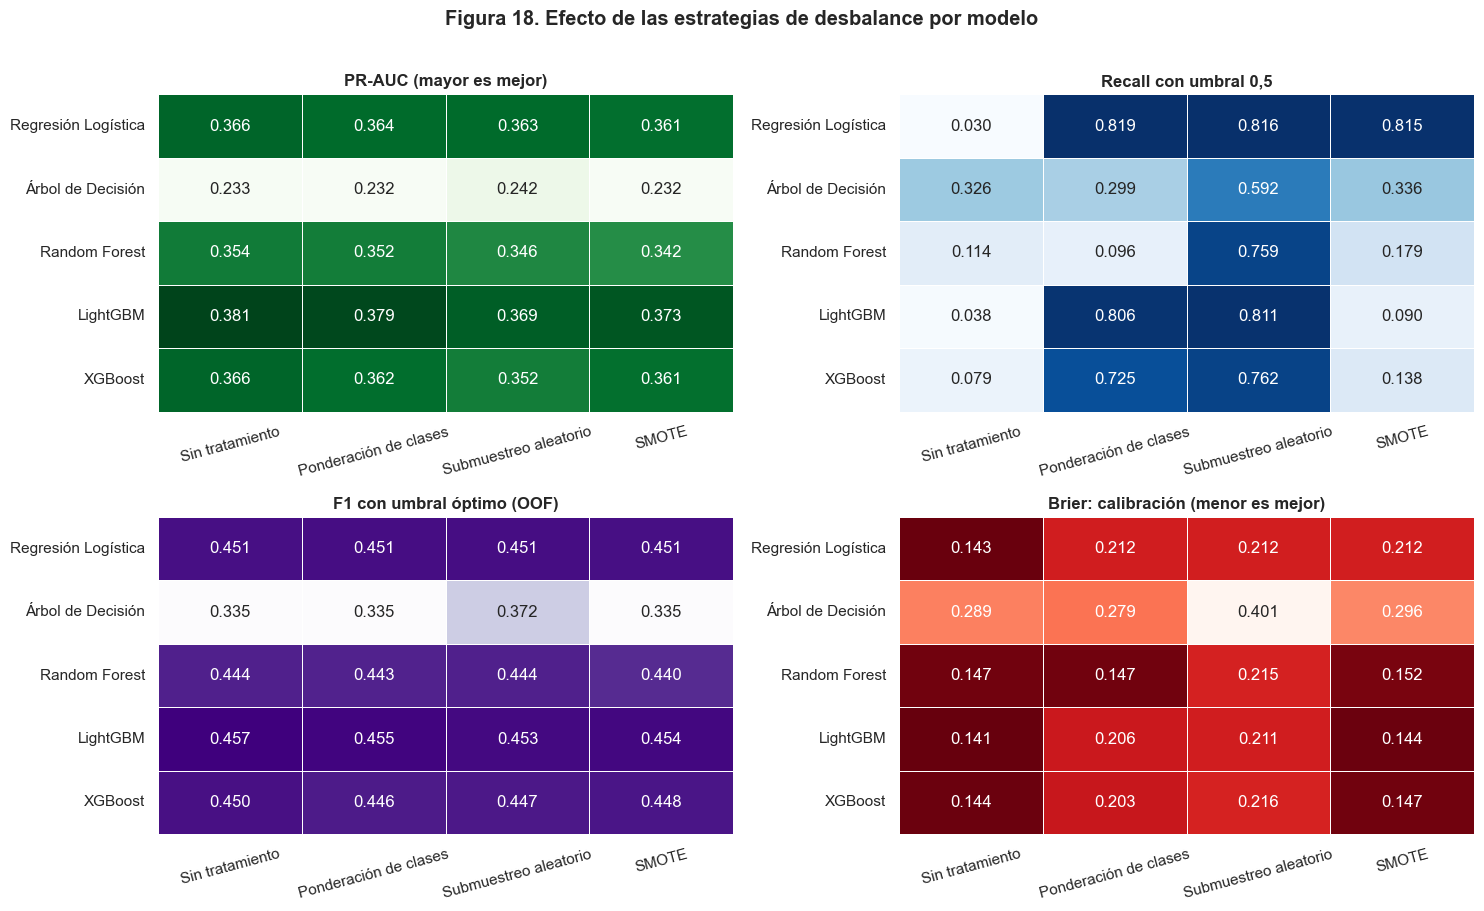

In [11]:
modelos_reales = [m for m in MODELOS if m != "dummy"]
claves = [(m, e) for m in modelos_reales for e in ESTRATEGIAS]
tabla_desbalance = tabla_resultados(claves)
umbrales = [umbral_f1_optimo(y, resultados[k]["oof"]) for k in claves]
tabla_desbalance["Umbral óptimo (F1)"] = [u for u, _ in umbrales]
tabla_desbalance["F1 con umbral óptimo"] = [f for _, f in umbrales]
guardar_tabla(tabla_desbalance, "mod_desbalance")

paneles = [("PR-AUC", "PR-AUC (mayor es mejor)", "Greens"),
           ("Recall (no-show)", "Recall con umbral 0,5", "Blues"),
           ("F1 con umbral óptimo", "F1 con umbral óptimo (OOF)", "Purples"),
           ("Brier", "Brier: calibración (menor es mejor)", "Reds_r")]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (col, titulo, cmap) in zip(axes.flat, paneles):
    matriz = tabla_desbalance.pivot(index="Modelo", columns="Estrategia", values=col)
    matriz = matriz.loc[[MODELOS[m][1] for m in modelos_reales], list(ESTRATEGIAS.values())]
    sns.heatmap(matriz, annot=True, fmt=".3f", cmap=cmap, cbar=False, linewidths=0.5, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Figura 18. Efecto de las estrategias de desbalance por modelo", fontweight="bold", y=1.01)
fig.tight_layout()
guardar_figura(fig, "mod_04_desbalance_heatmaps")
plt.show()

### 4.2. Diferencias pareadas respecto de "sin tratamiento"

Como todas las configuraciones usan los mismos folds, se puede calcular para cada fold la diferencia de PR-AUC entre una estrategia y la variante sin tratamiento del mismo modelo. Si el intervalo de esas diferencias incluye el cero, la estrategia no produce una mejora consistente.

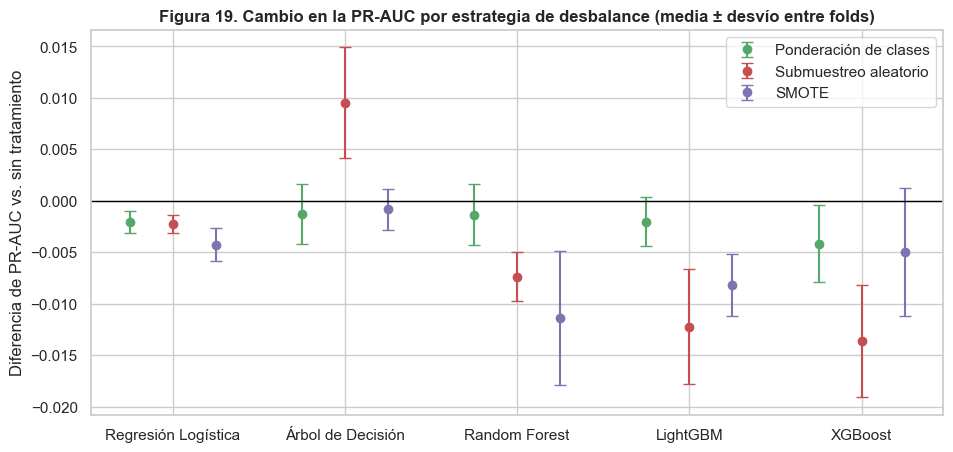

,Δ PR-AUC (media),Δ Brier (media),"Δ Recall@0,5 (media)",Tiempo relativo
Estrategia,,,,
Ponderación de clases,-0.0022,0.0363,0.4314,1.0558
SMOTE,-0.0059,0.0170,0.1942,2.6593
Submuestreo aleatorio,-0.0052,0.0781,0.6303,0.6648


In [12]:
filas = []
for modelo in modelos_reales:
    base = resultados[(modelo, "ninguna")]["por_fold"].set_index("fold")
    for estrategia in [e for e in ESTRATEGIAS if e != "ninguna"]:
        pf = resultados[(modelo, estrategia)]["por_fold"].set_index("fold")
        dif = pf["pr_auc"] - base["pr_auc"]
        filas.append({"Modelo": MODELOS[modelo][1], "Estrategia": ESTRATEGIAS[estrategia],
                      "Δ PR-AUC (media)": dif.mean(), "Δ PR-AUC (desvío)": dif.std(),
                      "Folds con mejora": int((dif > 0).sum()),
                      "Δ Brier (media)": (pf["brier"] - base["brier"]).mean(),
                      "Δ Recall@0,5 (media)": (pf["recall"] - base["recall"]).mean(),
                      "Tiempo relativo": pf["segundos_ajuste"].sum() / base["segundos_ajuste"].sum()})
diferencias = pd.DataFrame(filas)
guardar_tabla(diferencias, "mod_desbalance_diferencias")

fig, ax = plt.subplots(figsize=(11, 5))
estrategias_tr = [ESTRATEGIAS[e] for e in ESTRATEGIAS if e != "ninguna"]
paleta_e = dict(zip(estrategias_tr, ["#55A868", "#C44E52", "#8172B2"]))
for i, est in enumerate(estrategias_tr):
    sub = diferencias[diferencias["Estrategia"] == est].set_index("Modelo").loc[[MODELOS[m][1] for m in modelos_reales]]
    x = np.arange(len(sub)) + (i - 1) * 0.25
    ax.errorbar(x, sub["Δ PR-AUC (media)"], yerr=sub["Δ PR-AUC (desvío)"], fmt="o", capsize=4,
                color=paleta_e[est], label=est)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(np.arange(len(modelos_reales)))
ax.set_xticklabels([MODELOS[m][1] for m in modelos_reales])
ax.set_ylabel("Diferencia de PR-AUC vs. sin tratamiento")
ax.set_title("Figura 19. Cambio en la PR-AUC por estrategia de desbalance (media ± desvío entre folds)")
ax.legend()
guardar_figura(fig, "mod_05_desbalance_diferencias")
plt.show()

resumen_estrategias = diferencias.groupby("Estrategia")[["Δ PR-AUC (media)", "Δ Brier (media)",
                                                          "Δ Recall@0,5 (media)", "Tiempo relativo"]].mean()
guardar_tabla(resumen_estrategias, "mod_desbalance_resumen", index=True)
resumen_estrategias

### 4.3. ¿Por qué SMOTE casi no cambia el recall de los modelos de árboles?

En la Figura 18, SMOTE eleva fuertemente el recall con umbral 0,5 de la Regresión Logística, pero apenas modifica el de los modelos de árboles. La hipótesis es que los árboles **aprenden a reconocer los turnos sintéticos**, porque SMOTE genera valores fraccionarios en atributos que en los datos reales solo pueden ser enteros o binarios (por ejemplo, `diabetes = 0,4` o `2,7` turnos previos). Si es así, el modelo asigna alta probabilidad a lo "artificial" y no a los turnos reales con riesgo de ausencia.

Para verificarlo se usa el fold 0 como validación y el resto como entrenamiento, aplicando el preprocesamiento y SMOTE exactamente como dentro del pipeline:

1. Se mide qué proporción de los turnos sintéticos tiene valores fraccionarios en atributos enteros o binarios.
2. Se entrena un clasificador para distinguir turnos sintéticos de positivos reales: si lo logra con facilidad, los sintéticos son reconocibles.
3. Se compara la probabilidad que LightGBM entrenado con SMOTE asigna a los sintéticos y a los positivos reales.
4. Se repite el entrenamiento **redondeando** los atributos enteros de los sintéticos (aproximación a SMOTE-NC) para ver si las probabilidades se desplazan como se esperaría.

In [13]:
atributos = atributos_de("lightgbm")
en_val = folds == 0
pre = crear_pipeline("lightgbm").named_steps["preprocesador"]
X_aj = pre.fit_transform(train.loc[~en_val, atributos], y[~en_val])
X_va = pre.transform(train.loc[en_val, atributos])
y_aj = y[~en_val].to_numpy()

columnas = list(pre.get_feature_names_out())
enteras = [columnas.index(c) for c in columnas if c not in ("barrio", "tasa_ausencias_previas")]
X_sm, y_sm = SMOTE(random_state=config.SEED).fit_resample(X_aj, y_aj)
sinteticos = X_sm[len(X_aj):]
pct_fraccionarios = (np.mod(sinteticos[:, enteras], 1) != 0).any(axis=1).mean()

# ¿Se pueden distinguir los sintéticos de los positivos reales?
reales_pos = X_aj[y_aj == 1]
Z = np.r_[reales_pos, sinteticos]
etiqueta = np.r_[np.zeros(len(reales_pos)), np.ones(len(sinteticos))]
orden = np.random.default_rng(config.SEED).permutation(len(Z))
Z, etiqueta = Z[orden], etiqueta[orden]
corte = int(0.7 * len(Z))
detector = LGBMClassifier(random_state=config.SEED, verbose=-1).fit(Z[:corte], etiqueta[:corte])
auc_detector = roc_auc_score(etiqueta[corte:], detector.predict_proba(Z[corte:])[:, 1])

# Probabilidades de LightGBM entrenado con distintas versiones de los datos
X_sm_red = X_sm.copy()
X_sm_red[:, enteras] = np.round(X_sm_red[:, enteras])
filas = []
for nombre, (XX, yy) in {"Sin tratamiento": (X_aj, y_aj), "SMOTE": (X_sm, y_sm),
                         "SMOTE con enteros redondeados": (X_sm_red, y_sm)}.items():
    lgbm = LGBMClassifier(random_state=config.SEED, verbose=-1).fit(XX, yy)
    filas.append({
        "Datos de entrenamiento": nombre,
        "Prob. media en positivos reales": lgbm.predict_proba(reales_pos)[:, 1].mean(),
        "Prob. media en sintéticos": lgbm.predict_proba(sinteticos)[:, 1].mean() if nombre != "Sin tratamiento" else np.nan,
        "% de turnos de validación con prob. > 0,5": (lgbm.predict_proba(X_va)[:, 1] > 0.5).mean() * 100,
    })
analisis_smote = pd.DataFrame(filas)
guardar_tabla(analisis_smote, "mod_analisis_smote")

resumen["SMOTE: sintéticos con valores fraccionarios en atributos enteros"] = f"{pct_fraccionarios:.1%}"
resumen["SMOTE: ROC-AUC para distinguir sintéticos de reales"] = f"{auc_detector:.3f}"
print(f"Turnos sintéticos con valores fraccionarios en atributos enteros o binarios: {pct_fraccionarios:.1%}")
print(f"ROC-AUC de un clasificador que distingue sintéticos de positivos reales: {auc_detector:.3f}")
analisis_smote

Turnos sintéticos con valores fraccionarios en atributos enteros o binarios: 98.6%
ROC-AUC de un clasificador que distingue sintéticos de positivos reales: 0.996


,Datos de entrenamiento,Prob. media en positivos reales,Prob. media en sintéticos,"% de turnos de validación con prob. > 0,5"
0,Sin tratamiento,0.3180,NaN,1.6102
1,SMOTE,0.3527,0.9439,3.9367
2,SMOTE con enteros redondeados,0.5329,0.6966,47.5902


**Lectura:** la hipótesis se considera confirmada si se cumplen tres condiciones: casi todos los sintéticos tienen valores imposibles en los datos reales, el detector los distingue con una ROC-AUC cercana a 1, y LightGBM asigna a los sintéticos una probabilidad mucho mayor que a los positivos reales. En ese caso, el modelo de árboles aprende a reconocer la **firma artificial** de SMOTE en lugar del patrón de ausentismo, y por eso sus probabilidades sobre turnos reales casi no se desplazan. Al redondear los atributos enteros, la firma desaparece y las probabilidades sí se desplazan, como ocurre con la ponderación de clases. La Regresión Logística, al ser un modelo lineal, no puede aislar esos valores fraccionarios, y su comportamiento con SMOTE es similar al de las otras estrategias.

Esto confirma la limitación teórica de SMOTE con atributos discretos y explica por qué, en este problema, es la estrategia menos adecuada: no mejora la discriminación, distorsiona el comportamiento de los modelos de árboles y es la más costosa en tiempo.

**Lectura del experimento 2.** Para interpretar estos resultados hay que distinguir dos tipos de métricas:

- **Las estrategias de desbalance no mejoran la capacidad de ordenar los turnos por riesgo.** En la Regresión Logística, Random Forest, LightGBM y XGBoost, las tres estrategias reducen levemente la PR-AUC, y en la mayoría de los casos lo hacen en todos o casi todos los folds (Figura 19 y tabla de diferencias).
- **El recall con umbral 0,5 aumenta mucho** con ponderación de clases y con submuestreo. Lo que cambia es la escala de las probabilidades: el modelo supera 0,5 con más frecuencia. Es un efecto equivalente a **bajar el umbral de decisión**: el umbral que maximiza el F1 pasa de alrededor de 0,2 sin tratamiento a alrededor de 0,5 con estas estrategias.
- **La calibración empeora** (Brier mayor) con ponderación y submuestreo: las probabilidades dejan de representar la frecuencia real del no-show.
- **El F1 con umbral óptimo es prácticamente igual entre estrategias** para un mismo modelo. Una vez que se ajusta el umbral, la estrategia de desbalance no aporta.
- **SMOTE** es la estrategia más costosa y, en los modelos de árboles, casi no modifica las probabilidades, por la razón demostrada en la sección 4.3.
- **Excepción: el Árbol de Decisión con submuestreo** mejora de forma pequeña pero consistente. En pruebas adicionales sobre la muestra de desarrollo, la mejora se mantuvo aun con el árbol regularizado (tamaño mínimo de hoja de 20 y 100), y la ponderación de clases no la reprodujo. Por lo tanto, no se explica solo por una reducción del sobreajuste ni por el criterio de partición. Al no identificarse un mecanismo concluyente, se trata como un resultado empírico: para el árbol, la estrategia se incluirá como hiperparámetro en la optimización.

**Conclusión metodológica:** en este problema, el desbalance afecta a la **elección del umbral**, no a la capacidad de discriminación de los modelos. Por eso:

1. La selección de modelos se hace con PR-AUC, que no depende del umbral.
2. El umbral se ajustará explícitamente en el notebook 05, según el objetivo operativo (por ejemplo, un recall mínimo), sobre predicciones fuera de fold.
3. En la optimización con Optuna, para los modelos candidatos la estrategia se incluye como hiperparámetro solo entre "sin tratamiento" y "ponderación de clases". El submuestreo y SMOTE se descartan porque empeoran la PR-AUC de forma consistente; el submuestreo se conserva solo para el Árbol de Decisión.

## 5. Comparación global y selección de candidatos

### 5.1. Ranking de todas las configuraciones

In [14]:
ranking = tabla_desbalance.sort_values("PR-AUC", ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = "Posición"
guardar_tabla(ranking, "mod_ranking", index=True)
ranking[["Modelo", "Estrategia", "PR-AUC", "PR-AUC (desvío)", "ROC-AUC", "F1 con umbral óptimo",
         "Brier", "PR-AUC entrenamiento", "Segundos (5 folds)"]]

,Modelo,Estrategia,PR-AUC,PR-AUC (desvío),ROC-AUC,F1 con umbral óptimo,Brier,PR-AUC entrenamiento,Segundos (5 folds)
Posición,,,,,,,,,
1,LightGBM,Sin tratamiento,0.3814,0.0143,0.7442,0.4566,0.1415,0.4898,1.4840
2,LightGBM,Ponderación de clases,0.3794,0.0137,0.7428,0.4547,0.2061,0.4661,1.5742
3,LightGBM,SMOTE,0.3732,0.0127,0.7411,0.4535,0.1437,0.4412,3.9517
4,LightGBM,Submuestreo aleatorio,0.3692,0.0099,0.7394,0.4530,0.2107,0.4451,1.2045
5,XGBoost,Sin tratamiento,0.3659,0.0093,0.7352,0.4500,0.1441,0.5907,1.4671
6,Regresión Logística,Sin tratamiento,0.3658,0.0153,0.7361,0.4509,0.1429,0.3676,1.8227
7,Regresión Logística,Ponderación de clases,0.3637,0.0154,0.7360,0.4513,0.2116,0.3652,1.9299
8,Regresión Logística,Submuestreo aleatorio,0.3635,0.0148,0.7358,0.4511,0.2117,0.3652,1.2977
9,XGBoost,Ponderación de clases,0.3617,0.0102,0.7292,0.4457,0.2028,0.5795,1.5903


### 5.2. Criterio de selección

Para la etapa de optimización se seleccionan los **3 algoritmos con mejor PR-AUC**, tomando la mejor estrategia de cada uno. Se elige un candidato por algoritmo porque la optimización se hace por algoritmo, y la estrategia de desbalance volverá a evaluarse dentro de Optuna.

Para saber si las diferencias entre los candidatos son relevantes, se comparan **fold a fold** contra el mejor: si un candidato le gana en algunos folds o la diferencia media es menor que el desvío entre folds, las diferencias no son concluyentes y la optimización puede cambiar el orden.

Árbol de Decisión, aunque quede fuera de los 3 mejores, se conserva como **modelo interpretable de referencia**: es el algoritmo central de la Unidad III y permite extraer reglas explicables sobre el ausentismo.

In [15]:
mejor_por_modelo = (tabla_desbalance.sort_values("PR-AUC", ascending=False)
                    .drop_duplicates("Modelo").reset_index(drop=True))
nombre_a_clave = {v[1]: k for k, v in MODELOS.items()}
estrategia_a_clave = {v: k for k, v in ESTRATEGIAS.items()}
mejor_por_modelo["modelo"] = mejor_por_modelo["Modelo"].map(nombre_a_clave)
mejor_por_modelo["estrategia"] = mejor_por_modelo["Estrategia"].map(estrategia_a_clave)

top = mejor_por_modelo.head(3).copy()
top["Rol"] = "Candidato a optimizar"
if "arbol" not in top["modelo"].values:
    arbol = mejor_por_modelo[mejor_por_modelo["modelo"] == "arbol"].copy()
    arbol["Rol"] = "Referencia interpretable"
    top = pd.concat([top, arbol])

mejor = resultados[(top.iloc[0]["modelo"], top.iloc[0]["estrategia"])]["por_fold"].set_index("fold")["pr_auc"]
comparacion = []
for _, fila in top.iterrows():
    pf = resultados[(fila["modelo"], fila["estrategia"])]["por_fold"].set_index("fold")["pr_auc"]
    dif = pf - mejor
    comparacion.append({"Δ vs. mejor (media)": dif.mean(), "Folds en que supera al mejor": int((dif > 0).sum())})
candidatos = pd.concat([top.reset_index(drop=True), pd.DataFrame(comparacion)], axis=1)
candidatos = candidatos[["Rol", "modelo", "estrategia", "Modelo", "Estrategia", "PR-AUC", "PR-AUC (desvío)",
                         "ROC-AUC", "F1 con umbral óptimo", "Δ vs. mejor (media)", "Folds en que supera al mejor"]]
guardar_tabla(candidatos, "mod_candidatos")

resumen["Mejor configuración"] = f"{candidatos.iloc[0]['Modelo']} - {candidatos.iloc[0]['Estrategia']}"
resumen["Mejor PR-AUC (validación cruzada)"] = f"{candidatos.iloc[0]['PR-AUC']:.4f} ± {candidatos.iloc[0]['PR-AUC (desvío)']:.4f}"
resumen["Mejor ROC-AUC asociada"] = f"{candidatos.iloc[0]['ROC-AUC']:.4f}"
resumen["Candidatos para Optuna"] = ", ".join(candidatos.loc[candidatos["Rol"] == "Candidato a optimizar", "Modelo"])
candidatos

,Rol,modelo,estrategia,Modelo,Estrategia,PR-AUC,PR-AUC (desvío),ROC-AUC,F1 con umbral óptimo,Δ vs. mejor (media),Folds en que supera al mejor
0,Candidato a optimizar,lightgbm,ninguna,LightGBM,Sin tratamiento,0.3814,0.0143,0.7442,0.4566,0.0000,0
1,Candidato a optimizar,xgboost,ninguna,XGBoost,Sin tratamiento,0.3659,0.0093,0.7352,0.4500,-0.0156,0
2,Candidato a optimizar,logistica,ninguna,Regresión Logística,Sin tratamiento,0.3658,0.0153,0.7361,0.4509,-0.0157,0
3,Referencia interpretable,arbol,submuestreo,Árbol de Decisión,Submuestreo aleatorio,0.2424,0.0059,0.5958,0.3719,-0.1390,0


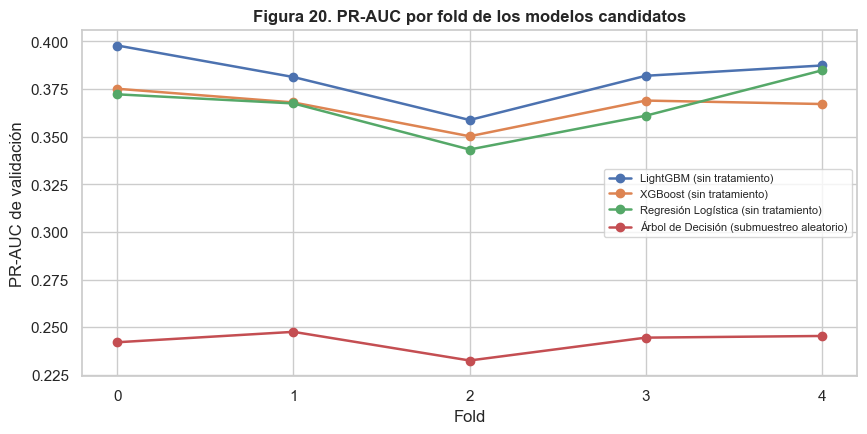

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for _, fila in candidatos.iterrows():
    pf = resultados[(fila["modelo"], fila["estrategia"])]["por_fold"]
    ax.plot(pf["fold"], pf["pr_auc"], marker="o", lw=1.8, label=f"{fila['Modelo']} ({fila['Estrategia'].lower()})")
ax.set_xticks(sorted(np.unique(folds)))
ax.set_xlabel("Fold")
ax.set_ylabel("PR-AUC de validación")
ax.set_title("Figura 20. PR-AUC por fold de los modelos candidatos")
ax.legend(fontsize=8)
guardar_figura(fig, "mod_06_candidatos_folds")
plt.show()

## 6. Trazabilidad: corridas registradas en MLflow

Todas las corridas quedaron registradas con sus parámetros, métricas (media y desvío de cada métrica), métricas por fold como artefacto, *hash* del dataset, semilla y *commit* de Git. La tabla siguiente se obtiene directamente de MLflow con `mlflow.search_runs`.

Para explorarlas en la interfaz web, ejecutar desde la raíz del repositorio:

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

y abrir <http://127.0.0.1:5000>. Conviene guardar capturas de la vista de comparación de corridas en `docs/capturas/` para el anexo del informe.

In [17]:
corridas = exportar_corridas(["baseline", "desbalance"], USAR_MUESTRA)
columnas = {"tags.mlflow.runName": "corrida", "params.modelo": "modelo", "params.estrategia": "estrategia",
            "metrics.pr_auc_media": "pr_auc", "metrics.pr_auc_desvio": "pr_auc_desvio",
            "metrics.roc_auc_media": "roc_auc", "metrics.brier_media": "brier",
            "tags.dataset_sha256": "dataset_sha256", "tags.etapa": "etapa", "run_id": "run_id"}
corridas = corridas[list(columnas)].rename(columns=columnas).sort_values("pr_auc", ascending=False)
corridas["dataset_sha256"] = corridas["dataset_sha256"].str[:12]

assert corridas["dataset_sha256"].nunique() == 1, "Hay corridas con datasets distintos"
guardar_tabla(corridas, "mod_corridas_mlflow")
resumen["Corridas registradas en MLflow"] = len(corridas)
print(f"Corridas registradas: {len(corridas)} | todas con el mismo dataset: {corridas['dataset_sha256'].iloc[0]}...")
corridas.head(10)

Corridas registradas: 21 | todas con el mismo dataset: 40d361e54c4c...


,corrida,modelo,estrategia,pr_auc,pr_auc_desvio,roc_auc,brier,dataset_sha256,etapa,run_id
16,lightgbm__ninguna,lightgbm,ninguna,0.3814,0.0143,0.7442,0.1415,40d361e54c4c,baseline,f6edcdc19fae42c2b01c478e413a1587
5,lightgbm__pesos,lightgbm,pesos,0.3794,0.0137,0.7428,0.2061,40d361e54c4c,desbalance,11f64f730371413496d8c9a138f55fc7
3,lightgbm__smote,lightgbm,smote,0.3732,0.0127,0.7411,0.1437,40d361e54c4c,desbalance,df9b37216509463494219ebb74617c84
4,lightgbm__submuestreo,lightgbm,submuestreo,0.3692,0.0099,0.7394,0.2107,40d361e54c4c,desbalance,579003a7409a4946a01a809b3003a88f
15,xgboost__ninguna,xgboost,ninguna,0.3659,0.0093,0.7352,0.1441,40d361e54c4c,baseline,6a1f32379d894362ac39fae2f2430541
19,logistica__ninguna,logistica,ninguna,0.3658,0.0153,0.7361,0.1429,40d361e54c4c,baseline,c523a6e78e0f430390f921d487984fdc
14,logistica__pesos,logistica,pesos,0.3637,0.0154,0.7360,0.2116,40d361e54c4c,desbalance,4c443e91abc44b13bdb2d8d5b694c936
13,logistica__submuestreo,logistica,submuestreo,0.3635,0.0148,0.7358,0.2117,40d361e54c4c,desbalance,00d8bbd035ac4ec1870744db2f6166f5
2,xgboost__pesos,xgboost,pesos,0.3617,0.0102,0.7292,0.2028,40d361e54c4c,desbalance,9d47ec693e744ffabbc5bdde153969b7
12,logistica__smote,logistica,smote,0.3615,0.0152,0.7342,0.2118,40d361e54c4c,desbalance,9b75212e8185445f8edaf07ada507616


### 6.1. Exportación del resumen

In [18]:
cifras = pd.DataFrame(list(resumen.items()), columns=["Indicador", "Valor"])
cols_rank = ["Modelo", "Estrategia", "PR-AUC", "PR-AUC (desvío)", "ROC-AUC", "Recall (no-show)",
             "F1 con umbral óptimo", "Umbral óptimo (F1)", "Brier", "PR-AUC entrenamiento", "Segundos (5 folds)"]
lineas = [
    "# Resumen del modelado baseline y del tratamiento del desbalance",
    "",
    f"**Datos utilizados:** {resumen['Datos utilizados']}",
    "",
    "## Cifras clave",
    "",
    tabla_markdown(cifras),
    "",
    "## Experimento 1: parámetros por defecto, sin tratamiento",
    "",
    tabla_markdown(tabla_baseline.drop(columns=["Estrategia"]).round(4)),
    "",
    "## Diagnóstico de sobreajuste",
    "",
    tabla_markdown(brecha.round(4), index=True),
    "",
    "## Experimento 2: diferencias pareadas respecto de sin tratamiento",
    "",
    tabla_markdown(diferencias.round(4)),
    "",
    "## Resumen por estrategia (promedio entre modelos)",
    "",
    tabla_markdown(resumen_estrategias.round(4), index=True),
    "",
    "## Ranking de todas las configuraciones",
    "",
    tabla_markdown(ranking[cols_rank].round(4), index=True),
    "",
    "## Candidatos seleccionados",
    "",
    tabla_markdown(candidatos.drop(columns=["modelo", "estrategia"]).round(4)),
    "",
]
ruta_resumen = config.TABLES_DIR / "mod_resumen.md"
ruta_resumen.write_text("\n".join(lineas), encoding="utf-8")
print(f"Resumen guardado en: {ruta_resumen}")
cifras

Resumen guardado en: C:\Users\poriglia\tfi-mineria-datos-noshow\reports\tables\mod_resumen.md


,Indicador,Valor
0,Datos utilizados,Dataset completo
1,Turnos de entrenamiento,"88,301"
2,Tasa de no-show (entrenamiento),20.10%
3,SMOTE: sintéticos con valores fraccionarios en...,98.6%
4,SMOTE: ROC-AUC para distinguir sintéticos de r...,0.996
5,Mejor configuración,LightGBM - Sin tratamiento
6,Mejor PR-AUC (validación cruzada),0.3814 ± 0.0143
7,Mejor ROC-AUC asociada,0.7442
8,Candidatos para Optuna,"LightGBM, XGBoost, Regresión Logística"
9,Corridas registradas en MLflow,21
